In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import defaultdict

PROJECT_DIR = '/content/drive/MyDrive/FAB_AMR_Project'
SIM_DIR     = f'{PROJECT_DIR}/04_simulator'
OUTPUT_DIR  = f'{SIM_DIR}/output'

print("✅ 준비 완료!")

Mounted at /content/drive
✅ 준비 완료!


In [2]:
# 1단계 결과 불러오기
with open(f'{OUTPUT_DIR}/fab_layout.json', 'r') as f:
    fab_layout = json.load(f)

meta   = fab_layout['meta']
grid_w = meta['grid_w']
grid_h = meta['grid_h']

print("=" * 40)
print("fab_layout.json 로드 완료")
print("=" * 40)
print(f"격자 크기:  {grid_w} x {grid_h}")
print(f"셀 크기:    {meta['cell_size']}mm")
print(f"장비:       {len(fab_layout['equipment'])}개")
print(f"obstacle:  {len(fab_layout['grid']['obstacles'])}개 셀")

fab_layout.json 로드 완료
격자 크기:  159 x 86
셀 크기:    2000mm
장비:       1116개
obstacle:  4690개 셀


In [3]:
# ── 맵 레이어 정의 ──
# 0 = 이동 가능 (free space)
# 1 = obstacle (장비)
# 2 = pickup 포트
# 3 = dropoff 포트

grid_map = np.zeros((grid_h, grid_w), dtype=np.int8)

# ── obstacle 등록 (장비) ──
for cell in fab_layout['grid']['obstacles']:
    gx, gy = cell
    if 0 <= gy < grid_h and 0 <= gx < grid_w:
        grid_map[gy][gx] = 1

print(f"obstacle 등록 완료: {(grid_map == 1).sum()}개 셀")

# ── 포트 위치 계산 + 등록 ──
# 포트는 장비 바로 옆 빈 셀에 배치
# 장비별 포트를 장비 중심 주변 4방향에서 찾음

def find_nearest_free_cell(gx, gy, grid_map):
    """장비 주변 4방향에서 가장 가까운 이동 가능 셀 반환"""
    directions = [(0,1),(0,-1),(1,0),(-1,0),
                  (1,1),(1,-1),(-1,1),(-1,-1)]
    for dist in range(1, 5):
        for dx, dy in directions:
            nx, ny = gx + dx*dist, gy + dy*dist
            if (0 <= nx < grid_map.shape[1] and
                0 <= ny < grid_map.shape[0] and
                grid_map[ny][nx] == 0):
                return nx, ny
    return None, None

# 장비별 포트 위치 계산
port_locations = {}   # eqp_name → (grid_x, grid_y)
port_cells     = []   # 포트 셀 목록

for eqp in fab_layout['equipment']:
    gx, gy = eqp['grid_x'], eqp['grid_y']
    px, py = find_nearest_free_cell(gx, gy, grid_map)

    if px is not None:
        port_locations[eqp['name']] = {
            "grid_x":   px,
            "grid_y":   py,
            "eqp_name": eqp['name'],
            "bay":      eqp['bay'],
            "tool":     eqp['tool'],
        }
        port_cells.append((px, py))
        # 픽업과 드롭오프 모두 같은 장비에서 가능
        grid_map[py][px] = 2

print(f"포트 등록 완료: {len(port_locations)}개")
print(f"\n맵 구성:")
print(f"  이동 가능(0): {(grid_map == 0).sum()}개 셀")
print(f"  obstacle(1):  {(grid_map == 1).sum()}개 셀")
print(f"  포트(2):      {(grid_map == 2).sum()}개 셀")

obstacle 등록 완료: 4690개 셀
포트 등록 완료: 1116개

맵 구성:
  이동 가능(0): 7868개 셀
  obstacle(1):  4690개 셀
  포트(2):      1116개 셀


In [4]:
# Grid Map 저장
np.save(f'{OUTPUT_DIR}/grid_map.npy', grid_map)

# 포트 위치도 JSON으로 저장
with open(f'{OUTPUT_DIR}/port_locations.json', 'w') as f:
    json.dump(port_locations, f, ensure_ascii=False, indent=2)

print("✅ 저장 완료!")
print(f"  grid_map.npy       → {OUTPUT_DIR}")
print(f"  port_locations.json → {OUTPUT_DIR}")

✅ 저장 완료!
  grid_map.npy       → /content/drive/MyDrive/FAB_AMR_Project/04_simulator/output
  port_locations.json → /content/drive/MyDrive/FAB_AMR_Project/04_simulator/output


/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 55152 (\N{HANGUL SYLLABLE HYIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 49353 (\N{HANGUL SYLLABLE SAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 45733 (\N{HANGUL SYLLABLE NEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1237/1866348432.py:42: UserWarning: Glyph 54028 (\N{HANGUL SYLLABLE PA}) missing from font(s) DejaVu Sans.
  plt.tight_

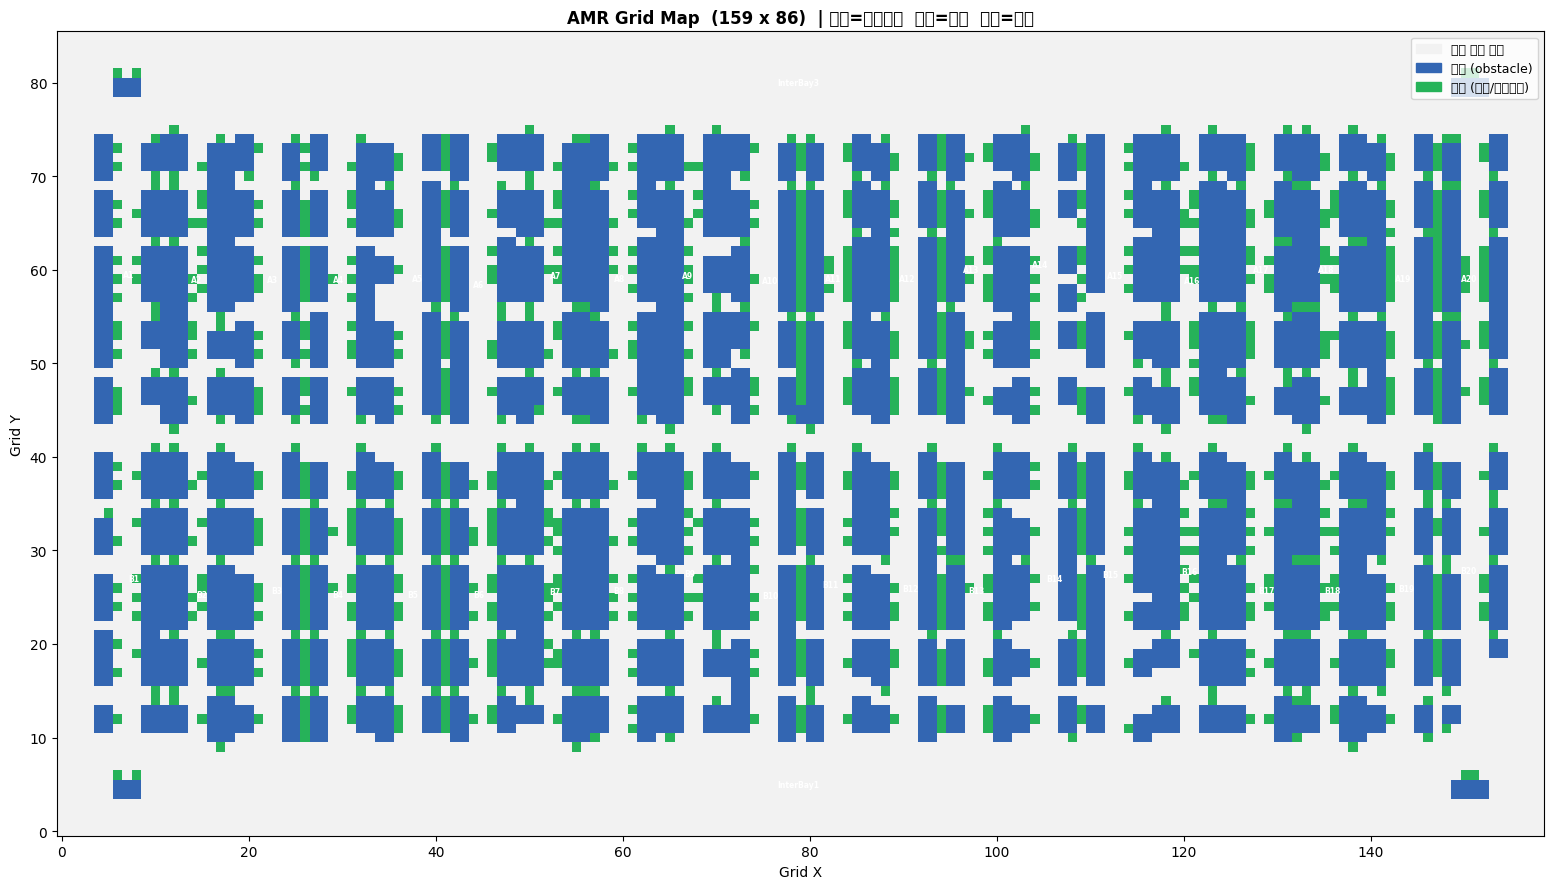

In [5]:
# 색상 정의
color_map = {
    0: [0.95, 0.95, 0.95],   # 이동 가능 - 연회색
    1: [0.20, 0.40, 0.70],   # obstacle  - 파랑
    2: [0.15, 0.70, 0.35],   # 포트      - 초록
}

rgb = np.array([[color_map[int(grid_map[r][c])]
                 for c in range(grid_w)]
                for r in range(grid_h)])

fig, ax = plt.subplots(figsize=(18, 9))
ax.imshow(rgb, origin='lower', aspect='equal')

# Bay 레이블
bay_centers = defaultdict(list)
for eqp in fab_layout['equipment']:
    bay_centers[eqp['bay']].append(
        (eqp['grid_x'], eqp['grid_y'])
    )

for bay, positions in bay_centers.items():
    cx = np.mean([p[0] for p in positions])
    cy = np.mean([p[1] for p in positions])
    ax.text(cx, cy, bay, fontsize=5.5,
            ha='center', va='center',
            color='white', fontweight='bold')

legend = [
    mpatches.Patch(color=[0.95,0.95,0.95], label='이동 가능 공간'),
    mpatches.Patch(color=[0.20,0.40,0.70], label='장비 (obstacle)'),
    mpatches.Patch(color=[0.15,0.70,0.35], label='포트 (픽업/드롭오프)'),
]
ax.legend(handles=legend, loc='upper right', fontsize=9)
ax.set_title(
    f"AMR Grid Map  ({grid_w} x {grid_h})  "
    f"| 흰색=이동가능  파랑=장비  초록=포트",
    fontsize=12, fontweight='bold'
)
ax.set_xlabel("Grid X")
ax.set_ylabel("Grid Y")
plt.tight_layout()
plt.show()

In [6]:
print("=" * 40)
print("2단계 체크리스트")
print("=" * 40)

checks = []

# 1. grid_map 로드
try:
    gm = np.load(f'{OUTPUT_DIR}/grid_map.npy')
    checks.append(("grid_map.npy 저장", True, f"{gm.shape}"))
except:
    checks.append(("grid_map.npy 저장", False, ""))

# 2. obstacle 존재
try:
    assert (gm == 1).sum() > 0
    checks.append(("obstacle 존재", True,
                   f"{(gm==1).sum()}개 셀"))
except:
    checks.append(("obstacle 존재", False, ""))

# 3. 포트 존재
try:
    assert (gm == 2).sum() > 0
    checks.append(("포트 존재", True,
                   f"{(gm==2).sum()}개 셀"))
except:
    checks.append(("포트 존재", False, ""))

# 4. 이동 가능 공간 존재
try:
    free = (gm == 0).sum()
    assert free > 0
    ratio = free / gm.size * 100
    checks.append(("이동 가능 공간", True,
                   f"{free}개 ({ratio:.1f}%)"))
except:
    checks.append(("이동 가능 공간", False, ""))

# 5. port_locations.json
try:
    with open(f'{OUTPUT_DIR}/port_locations.json') as f:
        pl = json.load(f)
    checks.append(("port_locations.json", True,
                   f"{len(pl)}개 포트"))
except:
    checks.append(("port_locations.json", False, ""))

for name, result, detail in checks:
    status = "✅" if result else "❌"
    detail_str = f"  ({detail})" if detail else ""
    print(f"  {status} {name}{detail_str}")

all_pass = all(r for _, r, _ in checks)
print()
if all_pass:
    print("🎉 2단계 완료! 3단계 A* 경로 탐색으로 이동!")
else:
    print("❌ 일부 실패. 위 내용 확인하세요.")

2단계 체크리스트
  ✅ grid_map.npy 저장  ((86, 159))
  ✅ obstacle 존재  (4690개 셀)
  ✅ 포트 존재  (1116개 셀)
  ✅ 이동 가능 공간  (7868개 (57.5%))
  ✅ port_locations.json  (1116개 포트)

🎉 2단계 완료! 3단계 A* 경로 탐색으로 이동!
